# Exploratory Data Analysis

#### Objective

The objective is to predict the students' O-level mathematics examination score to help the school to identify weaker students prior to the examination using the dataset provided. In your submission, you should evaluate at least 3 suitable models for estimating the students' scores.

#### Overall Evaluation

Once you have identified the most suitable model, find a way to compare the models against each other and explain which of these models is more suitable for the task.

In [2]:
#import modules
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

#load dataset
df = pd.read_csv('./data/regression_bonus_practice_data.csv')

df.head()

,index,number_of_siblings,direct_admission,CCA,learning_style,student_id,gender,tuition,final_test,n_male,n_female,age,hours_per_week,attendance_rate,sleep_time,wake_time,mode_of_transport,bag_color
0,0,0,Yes,Sports,Visual,ACN2BE,Female,No,69.0,14.0,2.0,16.0,10.0,91.0,22:00,6:00,private transport,yellow
1,1,2,No,Sports,Auditory,FGXIIZ,Female,No,47.0,4.0,19.0,16.0,7.0,94.0,22:30,6:30,private transport,green
2,2,0,Yes,NaN,Visual,B9AI9F,Male,No,85.0,14.0,2.0,15.0,8.0,92.0,22:30,6:30,private transport,white
3,3,1,No,Clubs,Auditory,FEVM1T,Female,Yes,64.0,2.0,20.0,15.0,18.0,NaN,21:00,5:00,public transport,yellow
4,4,0,No,Sports,Auditory,AXZN2E,Male,No,66.0,24.0,3.0,16.0,7.0,95.0,21:30,5:30,public transport,yellow


## 1. Preliminary Data Exploration

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15900 entries, 0 to 15899
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   index               15900 non-null  int64  
 1   number_of_siblings  15900 non-null  int64  
 2   direct_admission    15900 non-null  object 
 3   CCA                 12071 non-null  object 
 4   learning_style      15900 non-null  object 
 5   student_id          15900 non-null  object 
 6   gender              15900 non-null  object 
 7   tuition             15900 non-null  object 
 8   final_test          15405 non-null  float64
 9   n_male              15900 non-null  float64
 10  n_female            15900 non-null  float64
 11  age                 15900 non-null  float64
 12  hours_per_week      15900 non-null  float64
 13  attendance_rate     15122 non-null  float64
 14  sleep_time          15900 non-null  object 
 15  wake_time           15900 non-null  object 
 16  mode

In [4]:
print(df.nunique())
print()
print("Check Categorical and Boolean Column unique values:")
print(f"{df.direct_admission.name}:{df.direct_admission.unique()}")
print(f"{df.CCA.name}:{df.CCA.unique()}")
print(f"{df.learning_style.name}:{df.learning_style.unique()}")
print(f"{df.gender.name}:{df.gender.unique()}")
print(f"{df.tuition.name}:{df.tuition.unique()}")
print(f"{df.mode_of_transport.name}:{df.mode_of_transport.unique()}")
print(f"{df.bag_color.name}:{df.bag_color.unique()}")
print(f"{df.age.name}:{df.age.unique()}")

index                 15900
number_of_siblings        3
direct_admission          2
CCA                       7
learning_style            2
student_id            15000
gender                    2
tuition                   4
final_test               68
n_male                   32
n_female                 32
age                       6
hours_per_week           21
attendance_rate          61
sleep_time               13
wake_time                 5
mode_of_transport         3
bag_color                 6
dtype: int64

Check Categorical and Boolean Column unique values:
direct_admission:['Yes' 'No']
CCA:['Sports' nan 'Clubs' 'Arts' 'ARTS' 'SPORTS' 'CLUBS' 'NONE']
learning_style:['Visual' 'Auditory']
gender:['Female' 'Male']
tuition:['No' 'Yes' 'Y' 'N']
mode_of_transport:['private transport' 'public transport' 'walk']
bag_color:['yellow' 'green' 'white' 'red' 'blue' 'black']
age:[16. 15.  6.  5. -4. -5.]


In [5]:
df.describe()

,index,number_of_siblings,final_test,n_male,n_female,age,hours_per_week,attendance_rate
count,15900.000000,15900.000000,15405.000000,15900.000000,15900.000000,15900.000000,15900.000000,15122.000000
mean,7949.500000,0.886541,67.165401,13.880000,8.906038,15.213459,10.312579,93.270268
std,4590.078975,0.751346,13.977879,6.552584,6.663852,1.758941,4.461861,7.984230
min,0.000000,0.000000,32.000000,0.000000,0.000000,-5.000000,0.000000,40.000000
25%,3974.750000,0.000000,56.000000,10.000000,4.000000,15.000000,7.000000,92.000000
50%,7949.500000,1.000000,68.000000,14.000000,8.000000,15.000000,9.000000,95.000000
75%,11924.250000,1.000000,78.000000,18.000000,13.000000,16.000000,14.000000,97.000000
max,15899.000000,2.000000,100.000000,31.000000,31.000000,16.000000,20.000000,100.000000


In [6]:
df.shape

(15900, 18)

In [7]:
df.isnull().sum()

index                    0
number_of_siblings       0
direct_admission         0
CCA                   3829
learning_style           0
student_id               0
gender                   0
tuition                  0
final_test             495
n_male                   0
n_female                 0
age                      0
hours_per_week           0
attendance_rate        778
sleep_time               0
wake_time                0
mode_of_transport        0
bag_color                0
dtype: int64

In [8]:
print(f"Student IDs duplicated: {df['student_id'].duplicated().sum()}")
duplicated_df = df[df["student_id"].duplicated(keep=False)].sort_values(by="student_id")
duplicated_df.head(25)

Student IDs duplicated: 900


,index,number_of_siblings,direct_admission,CCA,learning_style,student_id,gender,tuition,final_test,n_male,n_female,age,hours_per_week,attendance_rate,sleep_time,wake_time,mode_of_transport,bag_color
5534,5534,0,No,Clubs,Auditory,00811H,Female,Yes,88.0,21.0,4.0,15.0,8.0,92.0,23:00,7:00,walk,green
12290,12290,0,No,Clubs,Auditory,00811H,Female,Yes,88.0,21.0,4.0,15.0,8.0,92.0,23:00,7:00,walk,white
12270,12270,1,No,Arts,Visual,0195IO,Female,No,52.0,8.0,22.0,16.0,15.0,99.0,22:00,6:00,private transport,yellow
13541,13541,1,No,Arts,Visual,0195IO,Female,No,52.0,8.0,22.0,16.0,15.0,99.0,22:00,6:00,private transport,yellow
4303,4303,0,No,Clubs,Auditory,02RSAH,Female,Yes,64.0,12.0,9.0,15.0,17.0,97.0,22:00,6:00,private transport,yellow
9172,9172,0,No,Clubs,Auditory,02RSAH,Female,Yes,64.0,12.0,9.0,15.0,17.0,97.0,22:00,6:00,private transport,green
8641,8641,0,No,Arts,Auditory,0FC4RY,Female,No,68.0,23.0,4.0,15.0,6.0,NaN,23:00,7:00,walk,blue
9791,9791,0,No,Arts,Auditory,0FC4RY,Female,No,68.0,23.0,4.0,15.0,6.0,100.0,23:00,7:00,walk,yellow
1405,1405,0,Yes,NaN,Visual,0JUGAF,Female,No,84.0,18.0,2.0,16.0,10.0,94.0,23:00,7:00,walk,red
6339,6339,0,Yes,NaN,Visual,0JUGAF,Female,No,84.0,18.0,2.0,16.0,10.0,94.0,23:00,7:00,walk,yellow


#### Data structure, assumptions and anomalies
* The dataset has 15900 rows and 18 columns.
* student_id is the primary key for this dataset. It requires cleanup due to presence of duplicate student_id.
* There is no datetime entry for the dataset, we will assume order of data entry to be by index number. This means bigger index numbers will contain the newer information and we will use keep last entry.
* There are null values for CCA. For CCA as it is categorical, null would be assumed as having no CCA and would be a categorised as None. 
* There are null values for final_test. We will need to drop the row if it is still null after data cleaning and preprocessing as we are predicting final_test scores and this column will be required for training.
* There are null values for attendance_rate. For attendance_rate, if is null, we will give the average based on data that has the same hours_per_week. Logically it is assumed that a higher attendance rate will lead to higher number of hours per week.
* Multiple data types for columns are reflected as objects, we will need to handle it to convert them to numerical or parse them as the correct type.
* For age, "-4", "-5", "5", "6" are likely to be data entry errors and since their count is low, these data rows will be dropped.

## 2. Univariate Analysis

#### Data cleaning

In [9]:
# Drop student id duplicates, opting to keep the assumed latest entry by using keep="last"
df_cleaned = df.sort_index()
df_cleaned = df.drop_duplicates(subset="student_id", keep="last")
print(df_cleaned.shape)

# Drop rows with age less than 15, as they are likely to be data entry errors
df_cleaned = df_cleaned[df_cleaned["age"] >= 15]
print(df_cleaned.shape)

# Fix NaN values
df_cleaned["CCA"].fillna("None", inplace=True)
# For attendance_rate, we can fill NaN values with the average attendance rate for students with similar hours_per_week
avg_attendance_by_hours = df.groupby('hours_per_week')['attendance_rate'].transform('mean')
df['attendance_rate'] = df['attendance_rate'].fillna(avg_attendance_by_hours)

# Fix inconsistent categorical/boolean values for CCA and tuition columns
df_cleaned['CCA'] = df_cleaned['CCA'].replace({'ARTS': 'Arts', 'SPORTS': 'Sports', 'CLUBS': 'Clubs', 'NONE': 'None'})
df_cleaned['tuition'] = df_cleaned['tuition'].replace({'Y': 'Yes', 'N': 'No'})

# Drop final_test_score rows with NaN values
df_cleaned.dropna(subset=["final_test"], inplace=True)
df_cleaned.describe()

(15000, 18)
(14565, 18)


/var/folders/sp/64pcmd2d017g7380v7snsn640000gn/T/ipykernel_39149/632807574.py:11: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_cleaned["CCA"].fillna("None", inplace=True)


,index,number_of_siblings,final_test,n_male,n_female,age,hours_per_week,attendance_rate
count,14109.000000,14109.000000,14109.000000,14109.000000,14109.000000,14109.000000,14109.000000,13413.000000
mean,8096.906726,0.886952,67.228081,13.860302,8.903182,15.500815,10.319016,93.295460
std,4582.754662,0.752309,13.967691,6.547474,6.657599,0.500017,4.462800,7.923274
min,0.000000,0.000000,32.000000,0.000000,0.000000,15.000000,0.000000,40.000000
25%,4153.000000,0.000000,56.000000,10.000000,4.000000,15.000000,7.000000,92.000000
50%,8160.000000,1.000000,68.000000,14.000000,8.000000,16.000000,9.000000,95.000000
75%,12086.000000,1.000000,78.000000,18.000000,13.000000,16.000000,14.000000,97.000000
max,15899.000000,2.000000,100.000000,31.000000,31.000000,16.000000,20.000000,100.000000


#### Visualising Distributions

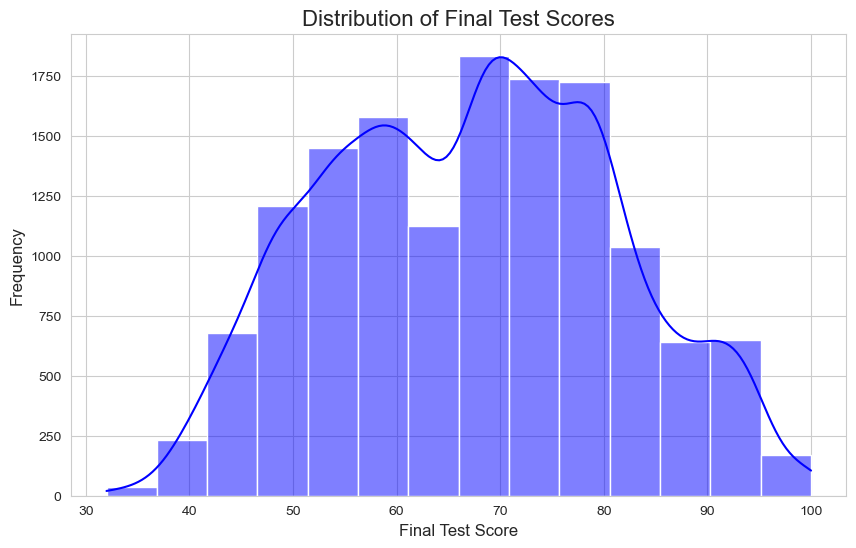

In [10]:
# draw histogram to display the final_test scores distribution
sns.set_style('whitegrid')

#histogram for final_test distribution
plt.figure(figsize=(10, 6))
sns.histplot(df_cleaned['final_test'], bins=14, kde=True, color='blue') #14 bins from 30 to 100 with increments of 5
plt.title('Distribution of Final Test Scores', fontsize=16)
plt.xlabel('Final Test Score', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.show()

Interpreting the histogram
In the histogram we plotted above, we can make several key observations about the 'final_test' target variable we aim to predict:

1. Central Tendency and Distribution

    The histogram shows that most frequent counts of final_test in the dataset cluster around a central range. The mean final_test is approximately 67.2, and the median is 68. This indicates that about half of the students have final_test below 68, and half are above.

2. Variability and Spread

    The final_test vary widely, as indicated by the standard deviation of about 14.0. The final_test scores range from a minimum of 32 to a maximum of 100, showing a broad spectrum of final_test scores.

3. Peaks and Common Prices

    The most common final_test (mode) is 65-70 bucket, which is where the highest peak of the histogram lies. This final_test score is the most frequent among the properties in the dataset.

4. Skewness

    The distribution follows a normal distribution pattern, characterized by symmetry around the mean. Most values cluster near the center, with decreasing frequency as values move toward the tails on both sides.


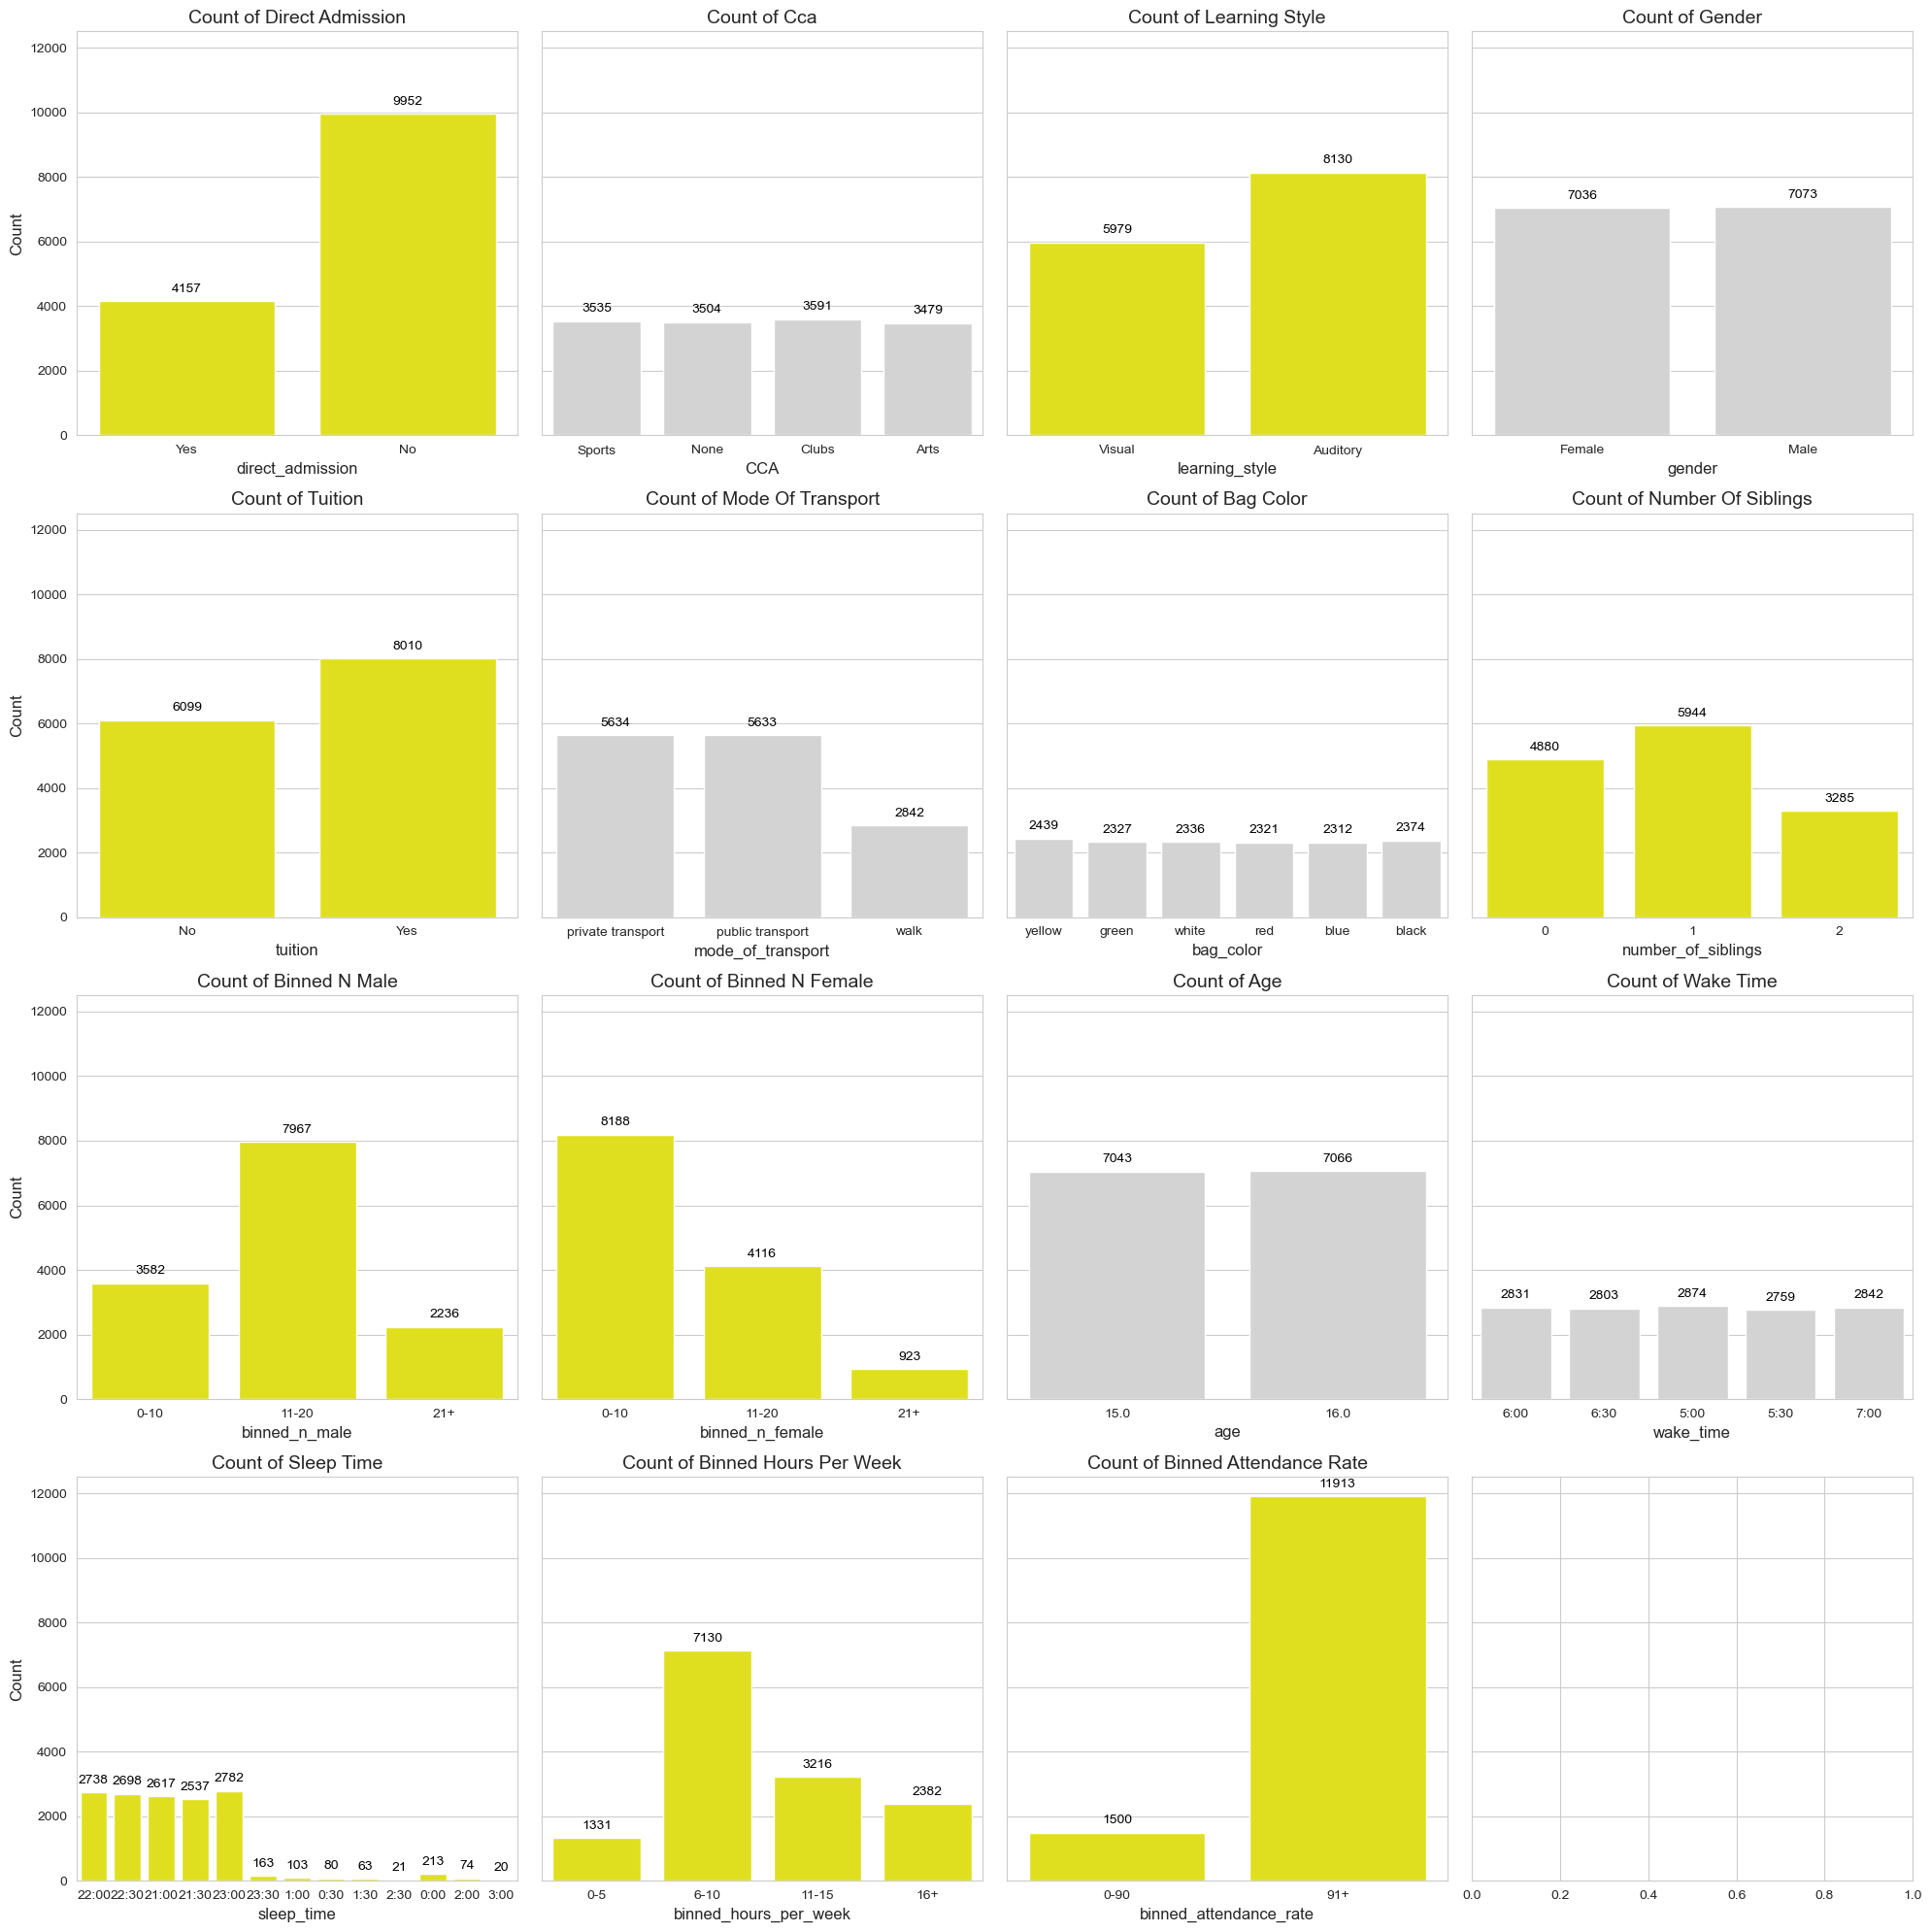

In [52]:
# Set the style
sns.set_style('whitegrid')

# Create Bins for use in plots
# Binned Number of Male/Female Classmates Count
BINNING_CONFIG = {
    "n_male": {"bins": [0, 10, 20, np.inf], "labels": ['0-10', '11-20', '21+']},
    "n_female": {"bins": [0, 10, 20, np.inf], "labels": ['0-10', '11-20', '21+']},
    "hours_per_week": {"bins": [0, 5, 10, 15, np.inf], "labels": ['0-5', '6-10', '11-15', '16+']},
    "attendance_rate": {"bins": [0, 90, np.inf], "labels": ['0-90', '91+']}
}

# Create binned columns for the specified features
for feature, config in BINNING_CONFIG.items():
    df[f"binned_{feature}"] = pd.cut(df[feature], bins=config["bins"], labels=config["labels"])
    
# Features to plot with colors: "feature name", "color"
PLOT_FEATURES = [
    ("direct_admission", "yellow"),
    ("CCA", "lightgray"),
    ("learning_style", "yellow"),
    ("gender", "lightgray"),
    ("tuition", "yellow"),
    ("mode_of_transport", "lightgray"),
    ("bag_color", "lightgray"),
    ("number_of_siblings", "yellow"),
    ("binned_n_male", "yellow"),
    ("binned_n_female", "yellow"),
    ("age", "lightgray"),
    ("wake_time", "lightgray"),
    ("sleep_time", "yellow"),
    ("binned_hours_per_week", "yellow"),
    ("binned_attendance_rate", "yellow")
]

# Define a helper function to plot countplots and manage subplot indices
def _plot_countplots(df, features, axes_col_max, figsize_x=20, figsize_y=20):
    '''Helper function to plot countplots for categorical features with subplot management.
    Args: df (pd.DataFrame): The cleaned DataFrame to plot.
        features (list): List of features to plot.
        axes_col_max (int): Maximum number of columns for subplots.
        figsize_x (int): Width of the figure.
        figsize_y (int): Height of the figure.
    '''
    #create figure and axes for subplots
    axes_row_max = (len(features) + axes_col_max - 1) // axes_col_max  # Calculate required rows based on number of features and columns
    fig, axes = plt.subplots(axes_row_max, axes_col_max, figsize=(figsize_x, figsize_y), sharey=True)

    axes_row = 0
    axes_col = 0
    for feature, color in features:
        sns.countplot(data=df, x=feature, ax=axes[axes_row, axes_col], color=color)
        axes[axes_row, axes_col].set_title(f"Count of {feature.replace('_', ' ').title()}", fontsize=14)
        axes[axes_row, axes_col].set_xlabel(feature, fontsize=12)
        axes[axes_row, axes_col].set_ylabel("Count", fontsize=12)
        
        # Update subplot indices
        axes_col += 1
        if axes_col == axes_col_max:
            axes_col = 0
            axes_row += 1

    # Add annotations to all subplots
    for ax in axes.flatten():
        for p in ax.patches:
            count = int(p.get_height())
            ax.annotate(f'{count}', (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='center', fontsize=10, color='black', xytext=(0, 9),
                        textcoords='offset points')
    plt.tight_layout()
    plt.show()

# draw our countplots
_plot_countplots(df_cleaned, PLOT_FEATURES, axes_col_max=4, figsize_x=20, figsize_y=20)

Interpreting trends from count plots.

Significant Class Imbalances: 
* We see a heavy skew toward students who did not enter via direct admission, with the "No" group being more than double the size of the "Yes" group. 
* "Auditory" learners are noticeably more common than "Visual" learners, 
* A larger majority of students attend tuition, "Yes" compared to those who do not, "No". 
* For transport, "private transport" and "public transport" are equally dominant, while those who "walk" make up exactly half of either group.
* The most common number of siblings is 1 compared to 0 and 2.
* The most common number of male classmates is "11-20" compared to "0-10" and "21+".
* The most common number of male classmates is "0-10" compared to "11-20" and "21+".
* The majority of students sleep before "23:30" with the remaining having small counts after "23:30".
* The most common number of hours per week is "6-10" and the least is "0-5".
* The majority of students have an attendance rate of 91% and above.

Highly Uniform Distributions: 
* The dataset is incredibly well-balanced between "Female" and "Male" students.
* The four choices in CCA are uniformly distributed, hovering right around students each
* All six Bag Color variations display a flat distribution ranging tightly between and instances.
* Majority of the ages are evenly split between "15" and "16".
* The wake time student count is evenly split across.

Sample sizes are large enough to eliminate random sampling bias, making observed trends reflective of the broader student population.

## 3. Bivariate Analysis

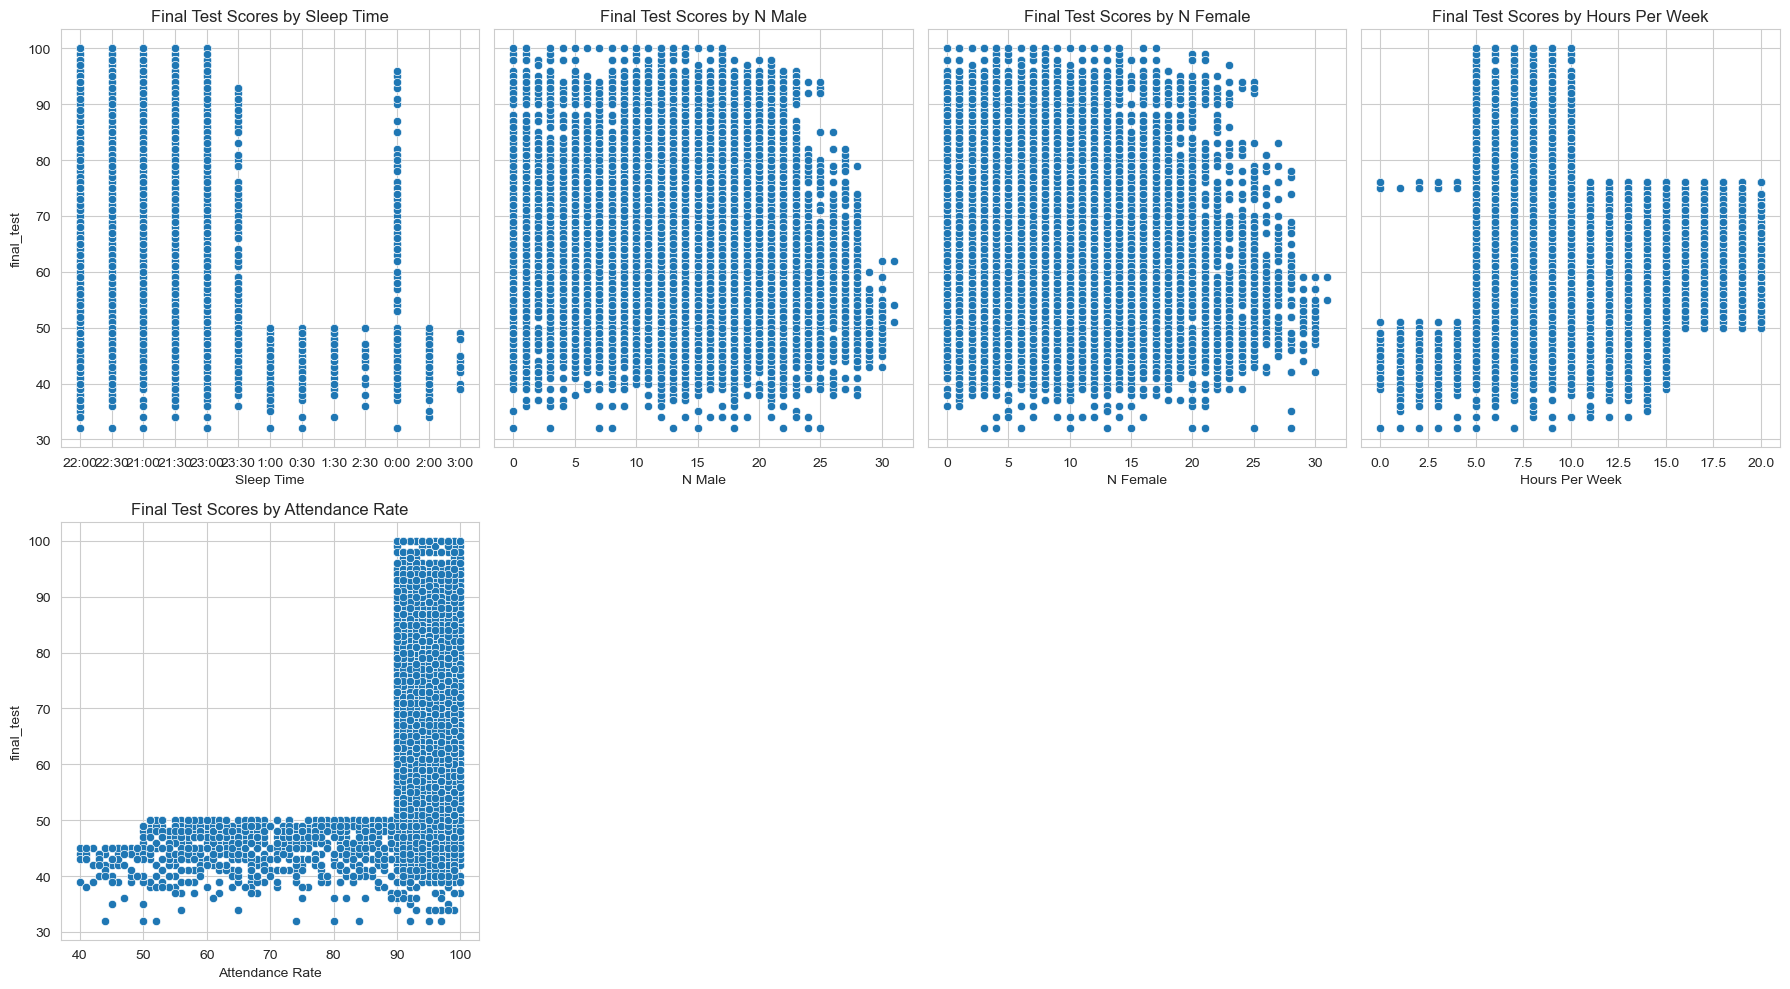

In [53]:
# Define features for scatter plot
features_to_plot = [
    "sleep_time",
    "n_male",
    "n_female",
    "hours_per_week",
    "attendance_rate"
]

# helper function to plot scatterplots for continuous features vs final_test scores
def _plot_scatterplots(
    df,
    features,
    figsize=(20, 10),
    ncols=4,
    color="tab:blue",
    title_prefix="Final Test Scores by "
):
    """
    Plot scatterplots of `final_test` vs. each feature in `features`.

    Parameters:
    - df (DataFrame): The cleaned DataFrame containing the data.
    - features (list): List of feature names (column names in df) to plot against `final_test`.
    - figsize (tuple): Figure size (width, height) in inches.
    - ncols (int): Number of columns in the subplot grid.
    - sharey (bool): Whether to share the y-axis across subplots.
    - color (str): Color for the scatterplot points.
    - title_prefix (str): Prefix for subplot titles (suffix will be the feature name).
    """
    
    # Calculate number of rows needed
    nfeatures = len(features)
    nrows = (nfeatures + ncols - 1) // ncols

    # Create subplots
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, sharey=True)

    # Flatten axes for easy iteration
    axes_flat = axes.flatten()

    # Iterate over features and plot
    for idx, feature in enumerate(features):
        ax = axes_flat[idx]

        sns.scatterplot(
            data=df,
            x=feature,
            y="final_test",
            ax=ax,
            color=color
        )

        # Set titles and labels
        ax.set_title(f"{title_prefix}{feature.replace('_', ' ').title()}")
        ax.set_xlabel(feature.replace('_', ' ').title())

        # Hide y-label for all but the first column
        if idx % ncols != 0:
            ax.set_ylabel("")

    # Hide any unused subplots
    for ax in axes_flat[nfeatures:]:
        ax.axis('off')

    # Adjust layout and display
    plt.tight_layout()
    plt.show()

# Call the helper function
_plot_scatterplots(
    df_cleaned,
    features=features_to_plot,
    figsize=(18, 10),
    ncols=4,
    color="tab:blue",
    title_prefix="Final Test Scores by "
)

Interpreting trends from scatter plots.

The features above in the scatter plots have a high number of unique values and are candidates for being analysed as a continuous variable against final_test scores.

The distribution of the scatter plot data however shows that the data points for each of these features do not follow linear or directional patterns but instead have values with wide consistent spreads. The datapoints also tend to drastically reflect an increase or decrease in the range of final_test scores after key levels.

sleep_time showed a sudden dip in maximum test score results for students that sleep after 23:30.
number of male and female classmates showed a cliff for max test score results past 20 respective classmates.
hours_per_week shows distint spreads from 0 to 5 hours, 5 to 10 hours and 10 to 20 hour ranges.
attendance_rate shows a sudden drop off below 90% attendance rate.

The conclusion is that it would be more beneficial to analyse the data by grouping them into bins for analysis as categorical features and use box plots to visualise the data.

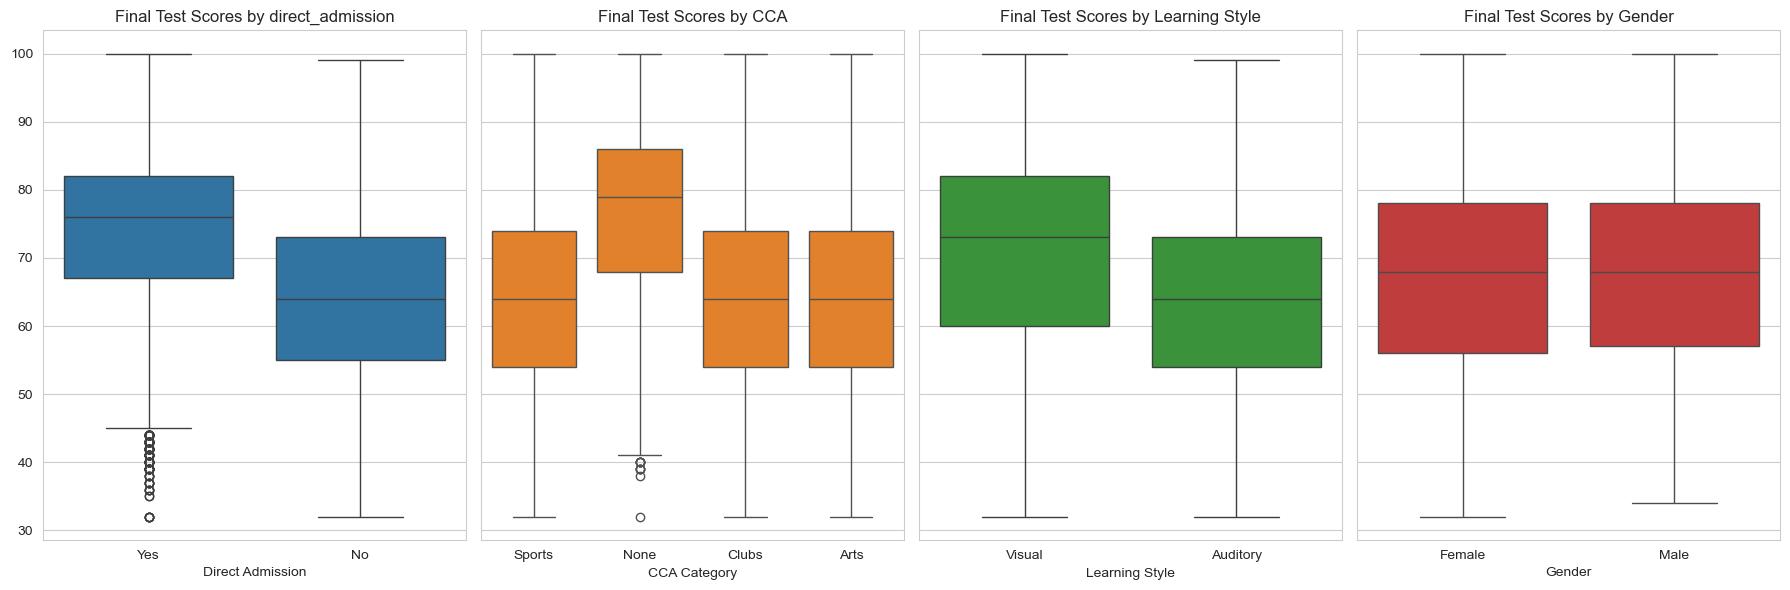

In [13]:
# Create side-by-side box plots for categorical features vs final_text scores
fig, axes = plt.subplots(1, 4, figsize=(18, 6), sharey=True)

# Plot Direct Admission
sns.boxplot(
    data=df_cleaned, 
    x="direct_admission", 
    y="final_test", 
    ax=axes[0],
    color="tab:blue"
)
axes[0].set_title("Final Test Scores by direct_admission")
axes[0].set_xlabel("Direct Admission")
axes[0].set_ylabel("") # Hide the middle y-label since all plots share the same y-axis

# Plot CCA
sns.boxplot(
    data=df_cleaned, 
    x="CCA", 
    y="final_test", 
    ax=axes[1],
    color="tab:orange"
)
axes[1].set_title("Final Test Scores by CCA")
axes[1].set_xlabel("CCA Category")
axes[1].set_ylabel("Final Test Score") # This label will show on the far left

# Plot Learning Style
sns.boxplot(
    data=df_cleaned, 
    x="learning_style", 
    y="final_test", 
    ax=axes[2],
    color="tab:green"
)
axes[2].set_title("Final Test Scores by Learning Style")
axes[2].set_xlabel("Learning Style")
axes[2].set_ylabel("") # Hide the middle y-label since all plots share the same y-axis

# Plot tuition
sns.boxplot(
    data=df_cleaned, 
    x="gender", 
    y="final_test", 
    ax=axes[3],
    color="tab:red"
)
axes[3].set_title("Final Test Scores by Gender")
axes[3].set_xlabel("Gender")
axes[3].set_ylabel("") # Hide the middle y-label since all plots share the same y-axis


# 4. Clean up the spacing and render
plt.tight_layout()
plt.show()

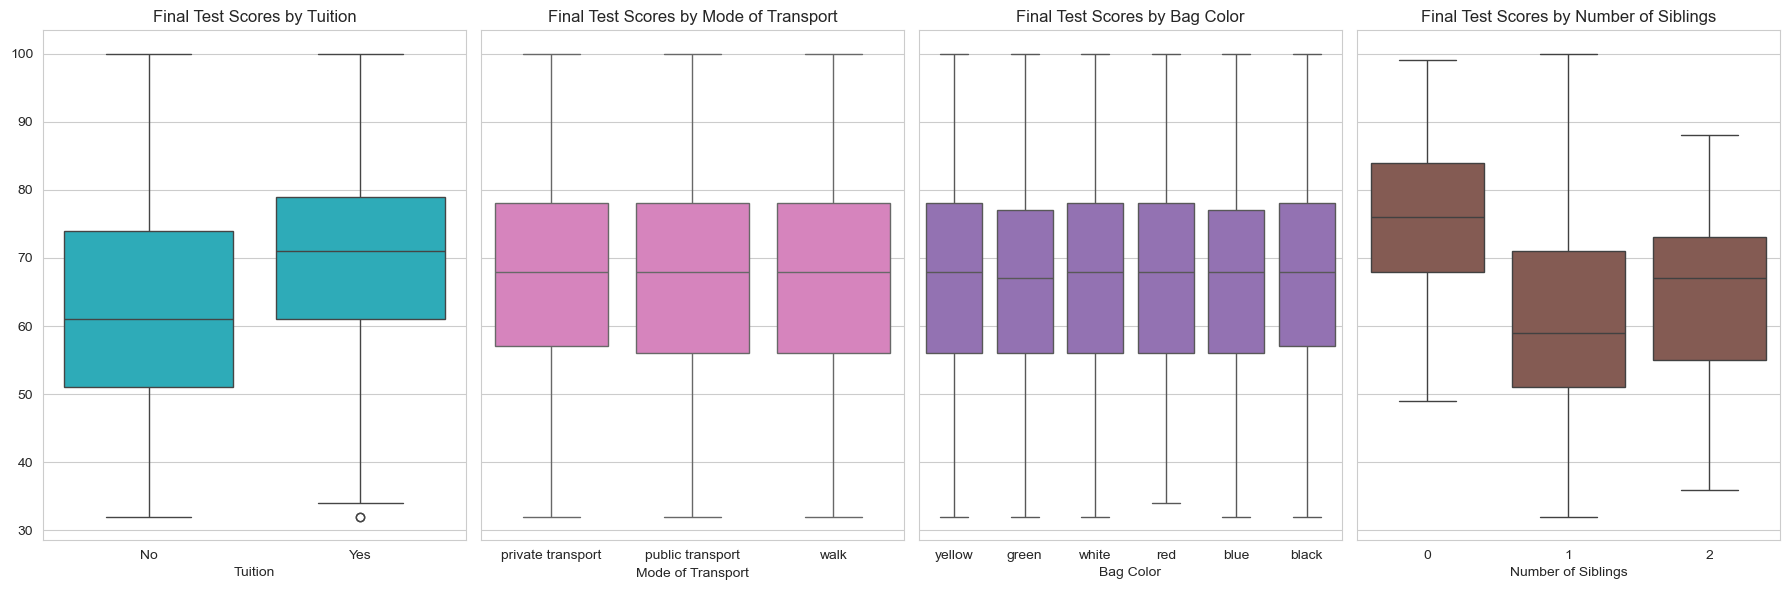

In [14]:
# Create side-by-side box plots for categorical features vs final_text scores
fig, axes = plt.subplots(1, 4, figsize=(18, 6), sharey=True)

# Plot tuition
sns.boxplot(
    data=df_cleaned, 
    x="tuition", 
    y="final_test", 
    ax=axes[0],
    color="tab:cyan"
)
axes[0].set_title("Final Test Scores by Tuition")
axes[0].set_xlabel("Tuition")
axes[0].set_ylabel("") # Hide the middle y-label since all plots share the same y-axis

# Plot mode of transport
sns.boxplot(
    data=df_cleaned, 
    x="mode_of_transport", 
    y="final_test", 
    ax=axes[1],
    color="tab:pink"
)
axes[1].set_title("Final Test Scores by Mode of Transport")
axes[1].set_xlabel("Mode of Transport")
axes[1].set_ylabel("") # Hide the middle y-label since all plots share the same y-axis

# Plot bag color
sns.boxplot(
    data=df_cleaned, 
    x="bag_color", 
    y="final_test", 
    ax=axes[2],
    color="tab:purple"
)
axes[2].set_title("Final Test Scores by Bag Color")
axes[2].set_xlabel("Bag Color")
axes[2].set_ylabel("") # Hide the middle y-label since all plots share the same y-axis

# Plot tuition
sns.boxplot(
    data=df_cleaned, 
    x="number_of_siblings", 
    y="final_test", 
    ax=axes[3],
    color="tab:brown"
)
axes[3].set_title("Final Test Scores by Number of Siblings")
axes[3].set_xlabel("Number of Siblings")
axes[3].set_ylabel("") # Hide the middle y-label since all plots share the same y-axis

# 4. Clean up the spacing and render
plt.tight_layout()
plt.show()

Interpreting box pLot for categorical variables
In the two sets of box plots we have plotted above, we can make several key observations about the relationship between each categorical and 'final_test' features.

Commentary on Key Predictors of Final Test Scores:
Direct admission, CCA, learning style, tuition and number of siblings show differentiated final test scores statistically and may be key predictors of final test scores.

1. Final Test Score Distribution

    The final test score distribution spread shows that when studects enter through direct admission or have no CCA, the spread is smaller as the bottom quartile values are higher then their counter parts. Males and students with tuition have marginally smaller spread for final test scores compared to their counter parts. 

2. Median Test Score

    The following feature and value pairs show significant higher median values than other options in their respective categories:
    * direct_admission: "Yes" has a higher median than "No"
    * CCA: "None" has a higher median than "Sports", "Clubs" and "Arts"
    * learning_style: "Visual" has a higher median than "Auditory"
    * tuition: "Yes" has a higher median than "No"
    * number_of_siblings: "0" has the highest median compared to "1" and "2" siblings

    Students with these feature values are likely to achieve better final test scores. Students with no CCA achieve the highest median score when compared against other categorical features.

3. Interquartile Range (IQR)

    The IQR, which is the range between the 25th and 75th percentiles, is slightly narrower for the following feature and value pairs:
    * direct_admission: "Yes" has a narrower IQR than "No"
    * CCA: "None" has a narrower IQR than "Sports", "Clubs" and "Arts"
    * tuition: "Yes" has a narrower IQR than "No"
    * number_of_siblings: "0" has a narrower IQR than "1" and "2" siblings

    Students with these feature values are performing more consistently with tighter range of final_test scores for the IQR.

4. Outliers

    There is the presence of outliers in the final test scores for direct_admissions, CCA and tuition. These outliers represent final test scores that deviate significantly from the general score trend, possibly due to other factors.

Commentary on Non-impactful indicators of Final Test Scores:
Gender, Mode of Transport, and Bag Color show uniform distributions. The medians and IQRs are almost identical across all variations, meaning these factors hold no observed statistical relationship with a student's final test score.
